In [101]:
import pandas_gbq
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ID = "project-4ac0cd29-6a3c-4bf7-a1e"

In [5]:
users = pandas_gbq.read_gbq(
    "SELECT * FROM `project-4ac0cd29-6a3c-4bf7-a1e.thelook_clean.users_clean`",
    project_id=PROJECT_ID
)
users.shape

Downloading: 100%|██████████|


(100000, 6)

In [7]:
items = pandas_gbq.read_gbq(
    "SELECT * FROM `project-4ac0cd29-6a3c-4bf7-a1e.thelook_clean.order_items_clean`",
    project_id=PROJECT_ID
)
items.shape

Downloading: 100%|██████████|


(179577, 13)

In [11]:
users.info()
items.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype              
---  ------          --------------   -----              
 0   id              100000 non-null  Int64              
 1   age             100000 non-null  Int64              
 2   gender          100000 non-null  object             
 3   country         100000 non-null  object             
 4   traffic_source  100000 non-null  object             
 5   created_at      100000 non-null  datetime64[us, UTC]
dtypes: Int64(2), datetime64[us, UTC](1), object(3)
memory usage: 4.8+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 179577 entries, 0 to 179576
Data columns (total 13 columns):
 #   Column             Non-Null Count   Dtype              
---  ------             --------------   -----              
 0   purchased_item_id  179577 non-null  Int64              
 1   order_id           179577 non-null  Int64             

In [13]:
users.head()
items.head()

,purchased_item_id,order_id,user_id,product_id,status,sale_price,created_at,category,brand,department,cost,margin,is_revenue
0,44337,30498,24540,755,Cancelled,28.950001,2025-09-08 02:06:36+00:00,Tops & Tees,None,Women,15.14085,13.81,False
1,71026,48788,39139,755,Complete,28.950001,2023-12-02 01:42:32+00:00,Tops & Tees,None,Women,15.14085,13.81,True
2,125296,86362,69050,755,Processing,28.950001,2024-11-25 23:23:52+00:00,Tops & Tees,None,Women,15.14085,13.81,False
3,55088,37843,30391,755,Returned,28.950001,2026-07-08 22:49:13+00:00,Tops & Tees,None,Women,15.14085,13.81,False
4,115258,79474,63561,755,Shipped,28.950001,2025-01-15 21:56:01+00:00,Tops & Tees,None,Women,15.14085,13.81,True


In [15]:
users.isna().sum()
items.isna().sum()

purchased_item_id      0
order_id               0
user_id                0
product_id             0
status                 0
sale_price             0
created_at             0
category               0
brand                153
department             0
cost                   0
margin                 0
is_revenue             0
dtype: int64

In [17]:
items['brand'] = items['brand'].fillna('Missing')

In [19]:
items.isna().sum()

purchased_item_id    0
order_id             0
user_id              0
product_id           0
status               0
sale_price           0
created_at           0
category             0
brand                0
department           0
cost                 0
margin               0
is_revenue           0
dtype: int64

In [37]:
revenue_items = items[items['is_revenue']]

In [45]:
revenue_items.shape

(99123, 13)

In [53]:
customers = revenue_items.groupby('user_id').agg(monetary = ('sale_price', 'sum'), frequency = ('order_id', 'nunique'), last_purchase = ('created_at', 'max'))
customers.shape
customers.head()

,monetary,frequency,last_purchase
user_id,,,
1,120.900000,1,2021-04-21 20:11:29+00:00
7,134.070007,1,2024-01-07 09:42:00+00:00
8,65.000000,1,2026-04-23 12:48:55+00:00
9,60.950001,2,2026-07-25 22:26:20+00:00
10,14.200000,1,2025-06-17 07:10:32+00:00


In [61]:
cutoff_date = pd.Timestamp('2026-11-16', tz = 'UTC')
customers['recency'] = (cutoff_date - customers['last_purchase']).dt.days
customers['recency'].describe()

count    52669.000000
mean       636.635725
std        606.422990
min          0.000000
25%        146.000000
50%        444.000000
75%        971.000000
max       2853.000000
Name: recency, dtype: float64

In [63]:
customers[['monetary', 'frequency', 'recency']].describe()

,monetary,frequency,recency
count,52669.000000,52669.000000,52669.000000
mean,112.404524,1.304714,636.635725
std,117.347522,0.589982,606.422990
min,0.020000,1.000000,0.000000
25%,36.000000,1.000000,146.000000
50%,72.989998,1.000000,444.000000
75%,149.420002,1.000000,971.000000
max,1418.530001,4.000000,2853.000000


In [130]:
(customers['recency'] <= 90).mean()

0.18468169131747328

In [132]:
(customers['recency'] <= 365).mean()

0.4449106685146861

In [134]:
(customers['recency'] <= 180).mean()

0.285936699007006

In [118]:
customers['is_recent'] = customers['recency'] <= 180
customers['is_repeat'] = customers['frequency'] >= 2
customers['is_recent'].mean()

0.285936699007006

In [116]:
customers['is_repeat'].mean()

0.24460308720499724

In [126]:
segments = customers.groupby(['is_repeat', 'is_recent']).agg(n_customers=('monetary', 'size'), avg_spend=('monetary', 'mean'), total_revenue=('monetary', 'sum'))
segments

n_customers   avg_spend  total_revenue
is_repeat is_recent                                        
False     False            29612   87.093873   2.579024e+06
          True             10174   84.220108   8.568554e+05
True      False             7997  191.325497   1.530030e+06
          True              4886  195.318195   9.543247e+05

In [138]:
segments['percent_customers'] = segments['n_customers'] / segments['n_customers'].sum() * 100
segments['percent_revenue'] = segments['total_revenue'] / segments['total_revenue'].sum() * 100
segments.round(1)

n_customers  avg_spend  total_revenue  pct_customers  \
is_repeat is_recent                                                         
False     False            29612       87.1      2579023.8           56.2   
          True             10174       84.2       856855.4           19.3   
True      False             7997      191.3      1530030.0           15.2   
          True              4886      195.3       954324.7            9.3   

                     pct_revenue  percent_customers  percent_revenue  
is_repeat is_recent                                                   
False     False             43.6               56.2             43.6  
          True              14.5               19.3             14.5  
True      False             25.8               15.2             25.8  
          True              16.1                9.3             16.1

In [146]:
segments.index = ['Old one-off', 'New', 'Possibly lost', 'Loyal']
segments

,n_customers,avg_spend,total_revenue,pct_customers,pct_revenue,percent_customers,percent_revenue
Old one-off,29612,87.093873,2.579024e+06,56.222826,43.562870,56.222826,43.562870
New,10174,84.220108,8.568554e+05,19.316866,14.473337,19.316866,14.473337
Possibly lost,7997,191.325497,1.530030e+06,15.183505,25.844080,15.183505,25.844080
Loyal,4886,195.318195,9.543247e+05,9.276804,16.119713,9.276804,16.119713


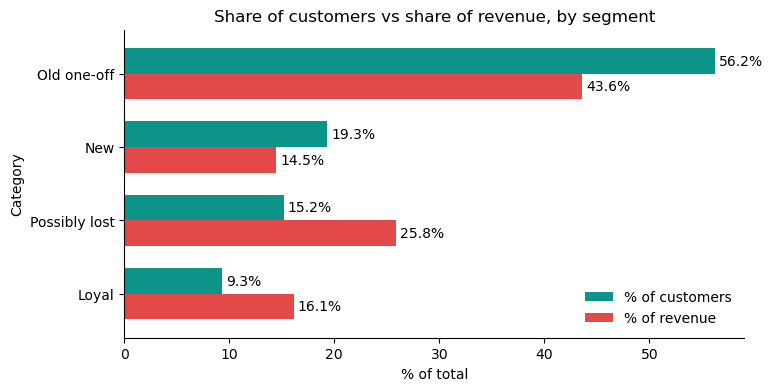

In [152]:
ax = segments[['percent_customers', 'percent_revenue']].plot(kind='barh', color=['#0d9488', '#e34948'], width=0.7, figsize=(8, 4))
ax.set_title('Share of customers vs share of revenue, by segment')
ax.set_xlabel('% of total')
ax.set_ylabel('Category')
ax.legend(['% of customers', '% of revenue'], frameon=False)
ax.spines[['top', 'right']].set_visible(False)
ax.invert_yaxis()
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f%%', padding=3)
plt.savefig('segment_share.png', dpi=200, bbox_inches='tight')

In [ ]:
## Recommendations by segment
"Old one-off": 
 - These are customers that made a single purchase over 180 days ago.
 - Account for 56.2% of the customers (29,612 customers).
 - Average spend of £87. Accounts for 43.6% of revenue. 
 - **LOW COST APPROACH** 
 - As they have only made one purchase long ago, it is not worth spending a lot of money trying to win them back. Try sending an outreach campaign email and see if they respond. If they don't, leave them. If they do, consider investing more money to win them back.

"New":
 - These are customers that made a single purchase under 180 days ago.
 - Account for 19.3% of the customers (10,174 customers).
 - Average spend of £84. Accounts for 14.5% of revenue.
 - **GET A SECOND PURCHASE, POSSIBLY MORE** 
 - As they are new customers, the top priority is trying to get them to make a second purchase, as only 24.5% of customers do so. Send a follow up second-order offer or a recommendation soon after their first order.

"Possibly lost":
 - These are customers that made multiple purchases, with the last purchase being over 180 days ago.
 - Account for 15.2% of the customers (7,997 customers).
 - Average spend of £191. Accounts for 25.8% of revenue.
 - **WIN THEM BACK**
 - Look at what they most commonly bought back when they were making purchases, and make offers based on that. They already know your business and what they want from it, so personalise the offer for them.

"Loyal":
 - These are customers that have made multiple purchases, with the last purchase being under 180 days ago.
 - Account for 9.3% of the customers (4,886).
 - Average spend of £195. Accounts for 16.1% of revenue.
 - **REWARD AND PROTECTION**
 - No need to discount as they keep making purchases. Give them rewards and perks when they are on the cusp of becoming "Possibly lost" (120+ days without purchase).

## Limitations                                                                                                                                       
 - 180 days is a business assumption. 90 and 365 days have been tested and gave groups of 18.5% to 44.5% respectively.
 - Average spend is calculated by total spend per customer, so people who have bought more may appear higher.
 - Everything suggested is a hypothesis.